## **Diferenciální evoluce**

V tomto úkolu implementuji **diferenciální evoluci (DE)** – evoluční algoritmus určený přímo pro spojitou optimalizaci. Na rozdíl od genetického algoritmu z předchozí úlohy se zde nepoužívá selekce rodičů ani klasické křížení, ale **mutace pomocí rozdílu vektorů** již existujících jedinců populace.

Jeden krok DE pro každého jedince $\mathbf{x}_i$ v populaci probíhá takto:
1. **Mutace:** vytvoří se mutační vektor $\mathbf{v}_i$ z ostatních jedinců populace.
2. **Křížení (binomické):** z cílového vektoru $\mathbf{x}_i$ a mutačního vektoru $\mathbf{v}_i$ vznikne zkušební vektor $\mathbf{u}_i$. Každá složka se vezme z $\mathbf{v}_i$ s pravděpodobností $CR$ (***crossover rate***), jinak z $\mathbf{x}_i$. Jedna náhodně zvolená složka $j_{rand}$ se vždy převezme z $\mathbf{v}_i$, aby se zkušební vektor nikdy nerovnal cílovému.
3. **Selekce:** zkušební vektor nahradí cílový pouze tehdy, pokud není horší (při minimalizaci $f(\mathbf{u}_i) \le f(\mathbf{x}_i)$). Kvalita jedince v populaci tak nikdy neklesá.

Algoritmus má dva základní parametry: **škálovací faktor $F$** (velikost kroku mutace) a **pravděpodobnost křížení $CR$**.

### **Import knihoven a definice testovacích funkcí**

Stejně jako v předchozí úloze minimalizuji tři standardní benchmarky v dimenzi $D = 10$:
* **Sphere** – hladká, konvexní, unimodální, minimum $0$ v $(0, \dots, 0)$, rozsah $[-5.12, 5.12]$
* **Rosenbrock** – úzké parabolické údolí, minimum $0$ v $(1, \dots, 1)$, rozsah $[-5, 10]$
* **Schwefel** – vysoce multimodální, minimum $0$ v $(420.9687, \dots, 420.9687)$, rozsah $[-500, 500]$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Set random seed for reproducibility of experiments
np.random.seed(42)

def sphere_function(x):
    # f(x) = sum(x_i^2)
    # Global minimum: f(0, ..., 0) = 0
    return np.sum(x**2)

def rosenbrock_function(x):
    # f(x) = sum(100 * (x_{i+1} - x_i^2)^2 + (x_i - 1)^2)
    # Global minimum: f(1, ..., 1) = 0
    return np.sum(100.0 * (x[1:] - x[:-1]**2)**2 + (x[:-1] - 1.0)**2)

def schwefel_function(x):
    # f(x) = 418.9829 * d - sum(x_i * sin(sqrt(|x_i|)))
    # Global minimum: f(420.9687, ..., 420.9687) = 0
    d = len(x)
    return 418.9829 * d - np.sum(x * np.sin(np.sqrt(np.abs(x))))

# Dictionary containing the functions and their respective domain boundaries
BENCHMARK_FUNCTIONS = {
    "Sphere": (sphere_function, -5.12, 5.12),
    "Rosenbrock": (rosenbrock_function, -5.0, 10.0),
    "Schwefel": (schwefel_function, -500.0, 500.0),
}

# Experiment settings
DIMENSION = 10
MAX_EVALUATIONS = 10000
POPULATION_SIZE = 50
NUM_RUNS = 10

### **Varianty mutace a jDE**

Varianty DE se liší způsobem tvorby mutačního vektoru:

* **Rand/1:** základem je náhodný jedinec, ke kterému se přičte vážený rozdíl dvou dalších náhodných jedinců. Silně podporuje průzkum prostoru (exploration).

  $\mathbf{v}_i = \mathbf{x}_{r1} + F \cdot (\mathbf{x}_{r2} - \mathbf{x}_{r3})$

* **Best/1:** základem je aktuálně nejlepší jedinec populace. Konvergence je rychlejší (exploitation), ale hrozí předčasná konvergence do lokálního minima.

  $\mathbf{v}_i = \mathbf{x}_{best} + F \cdot (\mathbf{x}_{r1} - \mathbf{x}_{r2})$

  Indexy $r1, r2, r3$ jsou vzájemně různé a různé od $i$.

* **jDE:** mutace Rand/1, ale parametry $F$ a $CR$ se **adaptují během běhu**. Každý jedinec nese vlastní $F_i$ a $CR_i$. Před vytvořením zkušebního vektoru se s pravděpodobností $\tau_1$ (resp. $\tau_2$) hodnota přegeneruje:

  $F_i = 0.1 + 0.8 \cdot rand_1$ s pravděpodobností $\tau_1$, jinak se ponechá,

  $CR_i = rand_2$ s pravděpodobností $\tau_2$, jinak se ponechá.

  Nové hodnoty se uchovají jen tehdy, pokud zkušební vektor uspěl v selekci.

**Použité parametry:**

| Varianta | $F$ | $CR$ | $\tau_1 = \tau_2$ |
| :--- | :--- | :--- | :--- |
| Rand/1 | 0.5 | 0.8 | – |
| Best/1 | 0.5 | 0.8 | – |
| jDE | počáteční 0.5 (rozsah 0.1 až 0.9) | počáteční 0.9 (rozsah 0 až 1) | 0.1 |

Hodnoty mimo definiční obor funkce se po mutaci ořezávají na jeho hranice.

In [2]:
def run_de(
    fitness_func, bounds, strategy="rand", adaptive=False,
    dimension=DIMENSION, max_evals=MAX_EVALUATIONS, pop_size=POPULATION_SIZE,
    F=0.5, CR=0.8, tau1=0.1, tau2=0.1,
):
    # strategy: "rand" (Rand/1) or "best" (Best/1)
    # adaptive: True enables jDE self-adaptation of F and CR
    min_b, max_b = bounds

    # Initialize population randomly within bounds
    population = np.random.uniform(min_b, max_b, size=(pop_size, dimension))
    fitness_scores = np.array([fitness_func(ind) for ind in population])
    evals_count = pop_size

    # Per-individual control parameters (only changed when adaptive)
    F_values = np.full(pop_size, F)
    CR_values = np.full(pop_size, CR)

    # History of the best-so-far value after each fitness evaluation
    best_so_far = np.min(fitness_scores)
    history = [best_so_far] * pop_size

    while evals_count < max_evals:
        best_idx = np.argmin(fitness_scores)

        for i in range(pop_size):
            if evals_count >= max_evals:
                break

            # jDE: randomly regenerate F and CR of this individual
            F_i, CR_i = F_values[i], CR_values[i]
            if adaptive:
                if np.random.rand() < tau1:
                    F_i = 0.1 + 0.8 * np.random.rand()
                if np.random.rand() < tau2:
                    CR_i = np.random.rand()

            # Mutation: pick distinct indices different from i
            candidates = [j for j in range(pop_size) if j != i]
            if strategy == "best":
                r1, r2 = np.random.choice(candidates, size=2, replace=False)
                mutant = population[best_idx] + F_i * (population[r1] - population[r2])
            else:
                r1, r2, r3 = np.random.choice(candidates, size=3, replace=False)
                mutant = population[r1] + F_i * (population[r2] - population[r3])
            mutant = np.clip(mutant, min_b, max_b)

            # Binomial crossover (at least one gene is taken from the mutant)
            cross_mask = np.random.rand(dimension) < CR_i
            cross_mask[np.random.randint(dimension)] = True
            trial = np.where(cross_mask, mutant, population[i])

            # Greedy selection
            trial_fitness = fitness_func(trial)
            evals_count += 1
            if trial_fitness <= fitness_scores[i]:
                population[i] = trial
                fitness_scores[i] = trial_fitness
                F_values[i], CR_values[i] = F_i, CR_i

            best_so_far = min(best_so_far, fitness_scores[i])
            history.append(best_so_far)

    return best_so_far, np.array(history)

### **Spuštění experimentů**

Každá varianta DE je pro každou testovací funkci spuštěna **10× nezávisle** s rozpočtem **10 000 evaluací** účelové funkce a populací o velikosti 50 jedinců. Ze všech běhů se spočítají statistiky nejlepšího nalezeného řešení a průměrná konvergenční křivka.

In [3]:
DE_VARIANTS = {
    "Rand/1": dict(strategy="rand", adaptive=False, F=0.5, CR=0.8),
    "Best/1": dict(strategy="best", adaptive=False, F=0.5, CR=0.8),
    "jDE": dict(strategy="rand", adaptive=True, F=0.5, CR=0.9, tau1=0.1, tau2=0.1),
}

def run_all_experiments():
    stats = {}
    curves = {}

    for func_name, (func, min_b, max_b) in BENCHMARK_FUNCTIONS.items():
        stats[func_name] = {}
        curves[func_name] = {}

        for variant_name, params in DE_VARIANTS.items():
            finals, histories = [], []
            for _ in range(NUM_RUNS):
                best, history = run_de(func, (min_b, max_b), **params)
                finals.append(best)
                histories.append(history[:MAX_EVALUATIONS])

            finals = np.array(finals)
            stats[func_name][variant_name] = {
                "Best": np.min(finals),
                "Worst": np.max(finals),
                "Mean": np.mean(finals),
                "Median": np.median(finals),
                "Std": np.std(finals),
            }
            curves[func_name][variant_name] = np.mean(histories, axis=0)

    return stats, curves

stats, curves = run_all_experiments()

### **Výsledky a porovnání konvergence**

Pro každou testovací funkci je uvedena tabulka statistik z 10 běhů a graf průměrné konvergence (osa Y v logaritmickém měřítku, cílem je minimalizace).

### **Sphere**

| Varianta algoritmu | Nejlepší | Nejhorší | Průměr | Medián | Směrod. odchylka |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Rand/1** | 6.4031e-10 | 6.7215e-09 | 2.2829e-09 | 1.3413e-09 | 2.0932e-09 |
| **Best/1** | 1.0771e-10 | 9.3783e-05 | 3.3987e-05 | 2.3470e-05 | 3.5395e-05 |
| **jDE** | 6.0253e-11 | 7.8454e-10 | 3.2943e-10 | 2.1519e-10 | 2.3204e-10 |


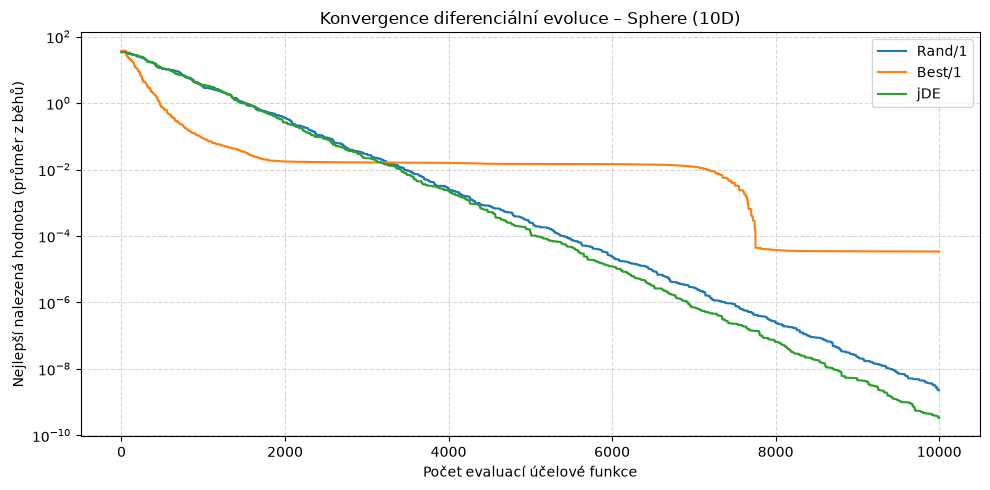

### **Rosenbrock**

| Varianta algoritmu | Nejlepší | Nejhorší | Průměr | Medián | Směrod. odchylka |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Rand/1** | 4.2646e+00 | 6.4347e+00 | 5.3385e+00 | 5.4931e+00 | 5.7430e-01 |
| **Best/1** | 3.0262e+00 | 7.2492e+01 | 2.5032e+01 | 1.2721e+01 | 2.4673e+01 |
| **jDE** | 1.4392e+00 | 6.9317e+00 | 5.1067e+00 | 5.2622e+00 | 1.4998e+00 |


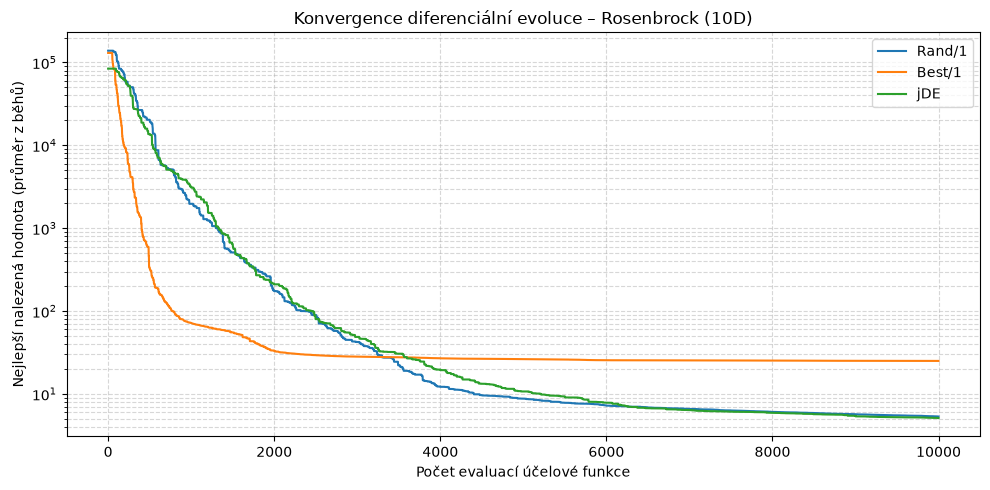

### **Schwefel**

| Varianta algoritmu | Nejlepší | Nejhorší | Průměr | Medián | Směrod. odchylka |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Rand/1** | 1.0002e+03 | 1.6798e+03 | 1.2805e+03 | 1.2876e+03 | 1.8410e+02 |
| **Best/1** | 5.9523e+02 | 1.4258e+03 | 1.0074e+03 | 1.0189e+03 | 3.2126e+02 |
| **jDE** | 1.7511e-01 | 1.2704e+02 | 5.0626e+01 | 4.4894e+01 | 4.7209e+01 |


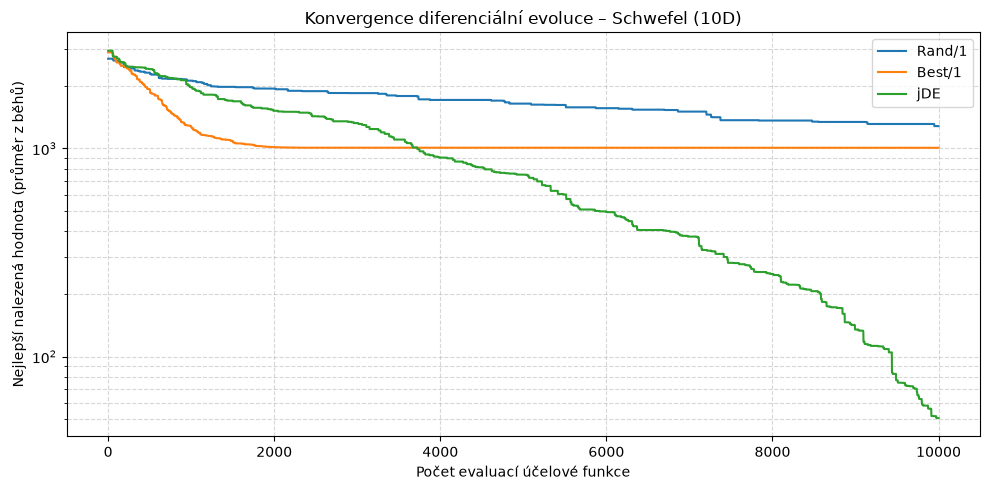

In [4]:
def display_results(stats, curves):
    for func_name in BENCHMARK_FUNCTIONS.keys():
        md = f"### **{func_name}**\n\n"
        md += "| Varianta algoritmu | Nejlepší | Nejhorší | Průměr | Medián | Směrod. odchylka |\n"
        md += "| :--- | :--- | :--- | :--- | :--- | :--- |\n"

        for var_name, s in stats[func_name].items():
            md += f"| **{var_name}** | {s['Best']:.4e} | {s['Worst']:.4e} | {s['Mean']:.4e} | {s['Median']:.4e} | {s['Std']:.4e} |\n"

        display(Markdown(md))

        # Convergence curves
        plt.figure(figsize=(10, 5))
        for var_name, curve in curves[func_name].items():
            # Log scale needs strictly positive values
            plt.plot(np.maximum(curve, 1e-16), label=var_name, linewidth=1.5)

        plt.yscale("log")
        plt.title(f"Konvergence diferenciální evoluce – {func_name} ({DIMENSION}D)")
        plt.xlabel("Počet evaluací účelové funkce")
        plt.ylabel("Nejlepší nalezená hodnota (průměr z běhů)")
        plt.grid(True, which="both", linestyle="--", alpha=0.5)
        plt.legend()
        plt.tight_layout()
        plt.show()

display_results(stats, curves)

### **Závěr a shrnutí úkolu**

Experimenty potvrdily, že volba mutační strategie zásadně ovlivňuje rovnováhu mezi **průzkumem** (exploration) a **dolaďováním** (exploitation).

**Best/1:** je nejrychlejší na začátku běhu, protože všichni jedinci směřují k aktuálně nejlepšímu řešení. Na všech třech funkcích ale brzy **stagnuje**. Na Sphere uvízl na hodnotě kolem $10^{-2}$ a výsledek $3.4 \cdot 10^{-5}$ je o několik řádů horší než u ostatních variant. Na Rosenbrocku skončil s průměrem $25.0$ a největším rozptylem (směrodatná odchylka $24.7$, nejhorší běh $72.5$). Na Schwefelovi zůstal kolem hodnoty $1000$ (průměr $1007$). Populace ztrácí diverzitu a nemá z čeho vytvářet nové smysluplné rozdíly vektorů.

**Rand/1:** konverguje pomaleji, ale **stabilně**. Na Sphere se přibližně lineárně (v logaritmickém měřítku) dostal na $2.3 \cdot 10^{-9}$ a na Rosenbrocku po cca 3 500 evaluacích předstihl Best/1 (průměr $5.34$ s nejmenším rozptylem z celé trojice). Na multimodálním Schwefelovi ale s pevným $F = 0.5$ a $CR = 0.8$ za daný rozpočet nestačil (průměr $1281$, nejhorší ze všech variant).

**jDE:** byl na všech funkcích **nejlepší nebo srovnatelný s nejlepším**. Na Sphere dosáhl přibližně 7× lepšího průměru než Rand/1 ($3.3 \cdot 10^{-10}$ oproti $2.3 \cdot 10^{-9}$). Na Rosenbrocku jsou Rand/1 a jDE prakticky stejné (průměr $5.11$ oproti $5.34$, rozdíl je menší než směrodatná odchylka) a žádná varianta nenašla globální minimum. jDE ale měl nejlepší jednotlivý běh ($1.44$). Zásadní rozdíl je u **Schwefela**: jDE po cca 3 800 evaluacích předstihl Best/1, dále trvale klesal a dosáhl průměru $50.6$ (nejlepší běh $0.175$, tedy téměř globální minimum). Je vidět, že ani po 10 000 evaluacích ještě nezkonvergoval. Adaptace $F$ a $CR$ umožňuje každému jedinci najít vhodnou velikost kroku a míru křížení pro aktuální fázi hledání, aniž by je bylo nutné ručně ladit pro konkrétní funkci.

**Shrnutí:**
* **Best/1** je vhodný pouze pro jednoduché unimodální úlohy a malý rozpočet, kde záleží na rychlém počátečním pokroku. U složitějších funkcí hrozí předčasná konvergence.
* **Rand/1** je robustní, ale výsledek závisí na ručně zvolených $F$ a $CR$.
* **jDE** se samoadaptací parametrů dosahuje nejlepších výsledků bez ladění a nejlépe zvládá multimodální krajinu. Navzdory mírně vyššímu rozptylu na Rosenbrocku je to nejvhodnější z testovaných variant.

Jelikož však vycházím pouze z 10 běhů a jedné velikosti populace, jedná se jen o orientační srovnání, nikoli o statisticky ověřený test.

## **Autor úkolu**
* Martin Koňařík m1_konarik@utb.cz

*Vytvořeno v rámci předmětu AP9EV na FAI UTB v roce 2026*